# Global Algorithm Comparison (kNN vs SVM vs RF)

This notebook implements the definitive statistical comparison between the best configurations of:
1. **Lazy Learning**: $k$-Nearest Neighbours (implemented from scratch in `KNNClassifier/`)
2. **Support Vector Machine**: SVM (`svmAlgorithm` via scikit-learn)
3. **Random Forest**: RF (`rfAlgorithm` via scikit-learn)

### Experimental Protocol (Demšar, 2006)
- Evaluated across $N=10$ folds (each fold treated as an independent testing set).
- **All data dynamically loaded from the experiment results CSVs** (zero hardcoded values).
- In both datasets, comparisons are conducted across two distinct evaluation perspectives:
  1. **Accuracy Block**: Models selected for highest predictive accuracy.
     - $10 \times 3$ Pivot Table (Folds $\times$ [kNN, SVM, RF])
     - Friedman Omnibus Test + Iman-Davenport correction
     - Critical Difference (CD) Diagram (Nemenyi test, $\alpha=0.05$) displayed inline
     - Pairwise Wilcoxon Signed-Rank Tests with **Holm-Bonferroni correction**
  2. **Efficiency Block**: Models selected for highest efficiency (lowest prediction latency).
     - $10 \times 3$ Pivot Table of Prediction Time (ms)
     - Friedman Omnibus Test (lower is better)
     - Critical Difference (CD) Diagram displayed inline
     - Pairwise Wilcoxon Signed-Rank Tests with **Holm-Bonferroni correction**
- Accuracy vs. Prediction Latency Pareto Trade-off Visualizations.
- Multi-metric comparison table dynamically compiled from fold evaluations.
- Comprehensive architectural discussion comparing Lazy vs. Eager Learning paradigms.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Setup paths dynamically
current_dir = Path().resolve()
if (current_dir / "Work2").exists():
    ROOT = current_dir / "Work2"
elif current_dir.name == "analysis":
    ROOT = current_dir.parent
else:
    ROOT = current_dir
sys.path.insert(0, str(ROOT))

from analysis.statistical_utils import (
    load_fold_results,
    load_summary_results,
    run_friedman_analysis,
    run_holm_adjusted_wilcoxon,
    RESULTS_DIR
)
from KNNClassifier import (
    friedman_test,
    wilcoxon_test,
    plot_critical_difference_diagram
)

COMPARISON_DIR = RESULTS_DIR / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)


## 1. Soybean Dataset: Global Comparison

We load the fold evaluations and summary statistics for all three algorithms on **Soybean**.

In [2]:
# Dynamically load fold results for all three algorithms on Soybean
df_knn_soy = load_fold_results("knn", "soybean")
df_svm_soy = load_fold_results("svm", "soybean")
df_rf_soy  = load_fold_results("rf", "soybean")

df_knn_soy_sum = load_summary_results("knn", "soybean")
df_svm_soy_sum = load_summary_results("svm", "soybean")
df_rf_soy_sum  = load_summary_results("rf", "soybean")

print(f"Loaded Soybean folds: kNN={len(df_knn_soy)}, SVM={len(df_svm_soy)}, RF={len(df_rf_soy)}")

Loaded Soybean folds: kNN=960, SVM=520, RF=360


### 1.1 Soybean: Best Models Selected by Accuracy & Statistical Evaluation

Selected Best Models on Soybean (by Accuracy):
  kNN: KNN(k=3, metric=canberra, voting=majority, retention=always_retain)
  SVM: SVM(kernel=rbf, C=1.0, gamma=0.1)
  RF:  RF(n=200, crit=log_loss, depth=10)

=== Soybean: 10-Fold Accuracy Matrix (Best Accuracy Models) ===


,kNN,SVM,Random Forest
Fold 0,0.916667,0.972222,0.972222
Fold 1,0.942029,0.927536,0.898551
Fold 2,0.938462,0.953846,0.953846
Fold 3,0.866667,0.906667,0.906667
Fold 4,0.943662,0.943662,0.943662
Fold 5,0.942029,0.956522,0.942029
Fold 6,0.926471,0.926471,0.941176
Fold 7,0.952381,0.952381,0.968254
Fold 8,0.895522,0.925373,0.925373
Fold 9,0.937500,0.953125,0.953125


Soybean Accuracy Friedman Omnibus Test:
  Chi2: 6.5000, p-value: 0.0388
  Iman-Davenport F: 4.3333, p-value: 0.0291
  Statistically significant: True


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,Random Forest,1.70,0.940491,0.024176,0.00,True,True
1,SVM,1.75,0.941780,0.019646,0.05,True,True
2,kNN,2.55,0.926139,0.026553,0.85,True,True



Critical Difference (N=10, k=3): 1.048


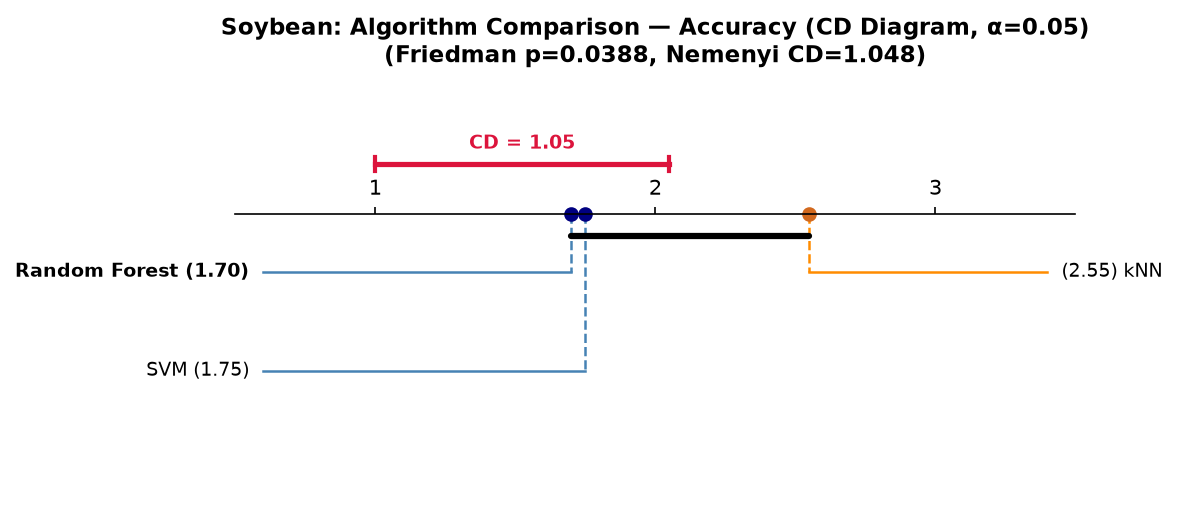


=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Accuracy) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,kNN,SVM,0.926139,0.941780,-0.015642,0.046875,0.140625,False
1,kNN,Random Forest,0.926139,0.940491,-0.014352,0.093750,0.187500,False
2,SVM,Random Forest,0.941780,0.940491,0.001290,1.000000,1.000000,False


In [3]:
# Identify best models dynamically based on mean accuracy
best_knn_soy_acc = df_knn_soy_sum.sort_values(by=["accuracy", "prediction_time"], ascending=[False, True]).iloc[0]["model"]
best_svm_soy_acc = df_svm_soy_sum.sort_values(by=["accuracy", "prediction_time"], ascending=[False, True]).iloc[0]["model"]
best_rf_soy_acc  = df_rf_soy_sum.sort_values(by=["accuracy", "prediction_time"], ascending=[False, True]).iloc[0]["model"]

print("Selected Best Models on Soybean (by Accuracy):")
print(f"  kNN: {best_knn_soy_acc}")
print(f"  SVM: {best_svm_soy_acc}")
print(f"  RF:  {best_rf_soy_acc}")

# Extract per-fold accuracy series
s_knn_soy_acc = df_knn_soy[df_knn_soy["model"] == best_knn_soy_acc].sort_values("fold")["accuracy"].values
s_svm_soy_acc = df_svm_soy[df_svm_soy["model"] == best_svm_soy_acc].sort_values("fold")["accuracy"].values
s_rf_soy_acc  = df_rf_soy[df_rf_soy["model"] == best_rf_soy_acc].sort_values("fold")["accuracy"].values

piv_acc_soy = pd.DataFrame({
    "kNN": s_knn_soy_acc,
    "SVM": s_svm_soy_acc,
    "Random Forest": s_rf_soy_acc,
}, index=[f"Fold {i}" for i in range(10)])

print("\n=== Soybean: 10-Fold Accuracy Matrix (Best Accuracy Models) ===")
display(piv_acc_soy)

# Statistical Analysis on Accuracy
cd_path_soy_algo_acc = COMPARISON_DIR / "soybean_algorithm_cd_accuracy.png"
fr_acc_soy = run_friedman_analysis(
    piv_acc_soy, higher_is_better=True,
    title="Soybean: Algorithm Comparison — Accuracy (CD Diagram, α=0.05)",
    save_path=str(cd_path_soy_algo_acc)
)
print("Soybean Accuracy Friedman Omnibus Test:")
print(f"  Chi2: {fr_acc_soy['friedman_chi2']:.4f}, p-value: {fr_acc_soy['friedman_p_value']:.4f}")
print(f"  Iman-Davenport F: {fr_acc_soy['iman_davenport_f']:.4f}, p-value: {fr_acc_soy['iman_davenport_p_value']:.4f}")
print(f"  Statistically significant: {fr_acc_soy['significant']}")
display(fr_acc_soy["summary_table"])

# Render CD Diagram Inline
print(f"\nCritical Difference (N=10, k=3): {fr_acc_soy['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_soy_algo_acc)))

# Pairwise Wilcoxon Tests with Holm-Bonferroni Correction
df_pairs_acc_soy = run_holm_adjusted_wilcoxon(piv_acc_soy)
print("\n=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Accuracy) ===")
display(df_pairs_acc_soy[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


### 1.2 Soybean: Best Models Selected by Efficiency & Statistical Evaluation

Selected Best Models on Soybean (by Efficiency):
  kNN: KNN(k=5, metric=euclidean, voting=majority, retention=never_retain)
  SVM: SVM(kernel=linear, C=1.0)
  RF:  RF(n=50, crit=gini, depth=5)

=== Soybean: 10-Fold Prediction Time Matrix (ms) (Best Efficiency Models) ===


,kNN,SVM,Random Forest
Fold 0,19.3257,1.6197,8.6582
Fold 1,21.9524,1.4581,8.1594
Fold 2,15.9585,1.4262,8.1029
Fold 3,18.5413,1.4584,8.0593
Fold 4,16.8248,1.5032,8.2985
Fold 5,16.4779,1.4430,8.4930
Fold 6,18.4386,1.4438,8.1540
Fold 7,16.8358,1.6016,8.0377
Fold 8,20.8651,1.4130,8.3385
Fold 9,15.6677,1.3843,8.4424


Soybean Efficiency Friedman Omnibus Test:
  Chi2: 20.0000, p-value: 4.5400e-05
  Iman-Davenport F: inf, p-value: 0.0000e+00
  Statistically significant: True


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,SVM,1.0,1.47513,0.078011,0.0,True,True
1,Random Forest,2.0,8.27439,0.207480,1.0,True,True
2,kNN,3.0,18.08878,2.125373,2.0,False,False



Critical Difference (N=10, k=3): 1.048


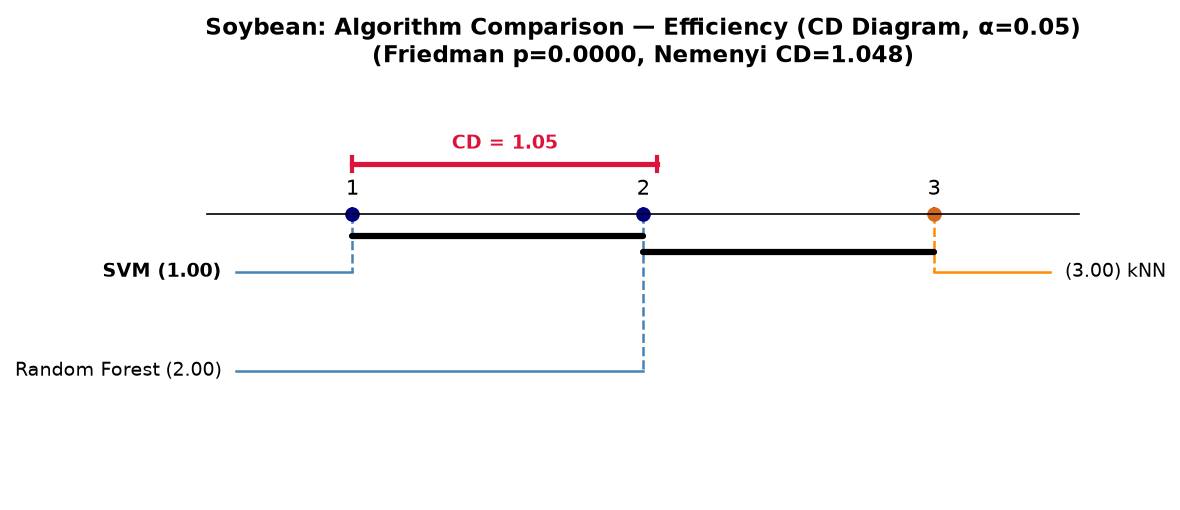


=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Efficiency) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,kNN,SVM,18.08878,1.47513,16.61365,0.001953,0.005859,True
1,kNN,Random Forest,18.08878,8.27439,9.81439,0.001953,0.005859,True
2,SVM,Random Forest,1.47513,8.27439,-6.79926,0.001953,0.005859,True


In [4]:
# Identify best models dynamically based on lowest prediction time
best_knn_soy_eff = df_knn_soy_sum.sort_values(by=["prediction_time", "accuracy"], ascending=[True, False]).iloc[0]["model"]
best_svm_soy_eff = df_svm_soy_sum.sort_values(by=["prediction_time", "accuracy"], ascending=[True, False]).iloc[0]["model"]
best_rf_soy_eff  = df_rf_soy_sum.sort_values(by=["prediction_time", "accuracy"], ascending=[True, False]).iloc[0]["model"]

print("Selected Best Models on Soybean (by Efficiency):")
print(f"  kNN: {best_knn_soy_eff}")
print(f"  SVM: {best_svm_soy_eff}")
print(f"  RF:  {best_rf_soy_eff}")

s_knn_soy_eff = df_knn_soy[df_knn_soy["model"] == best_knn_soy_eff].sort_values("fold")["prediction_time_ms"].values
s_svm_soy_eff = df_svm_soy[df_svm_soy["model"] == best_svm_soy_eff].sort_values("fold")["prediction_time_ms"].values
s_rf_soy_eff  = df_rf_soy[df_rf_soy["model"] == best_rf_soy_eff].sort_values("fold")["prediction_time_ms"].values

piv_eff_soy = pd.DataFrame({
    "kNN": s_knn_soy_eff,
    "SVM": s_svm_soy_eff,
    "Random Forest": s_rf_soy_eff,
}, index=[f"Fold {i}" for i in range(10)])

print("\n=== Soybean: 10-Fold Prediction Time Matrix (ms) (Best Efficiency Models) ===")
display(piv_eff_soy)

cd_path_soy_algo_eff = COMPARISON_DIR / "soybean_algorithm_cd_efficiency.png"
fr_eff_soy = run_friedman_analysis(
    piv_eff_soy, higher_is_better=False,
    title="Soybean: Algorithm Comparison — Efficiency (CD Diagram, α=0.05)",
    save_path=str(cd_path_soy_algo_eff)
)
print("Soybean Efficiency Friedman Omnibus Test:")
print(f"  Chi2: {fr_eff_soy['friedman_chi2']:.4f}, p-value: {fr_eff_soy['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F: {fr_eff_soy['iman_davenport_f']:.4f}, p-value: {fr_eff_soy['iman_davenport_p_value']:.4e}")
print(f"  Statistically significant: {fr_eff_soy['significant']}")
display(fr_eff_soy["summary_table"])

# Render CD Diagram Inline
print(f"\nCritical Difference (N=10, k=3): {fr_eff_soy['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_soy_algo_eff)))

df_pairs_eff_soy = run_holm_adjusted_wilcoxon(piv_eff_soy)
print("\n=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Efficiency) ===")
display(df_pairs_eff_soy[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


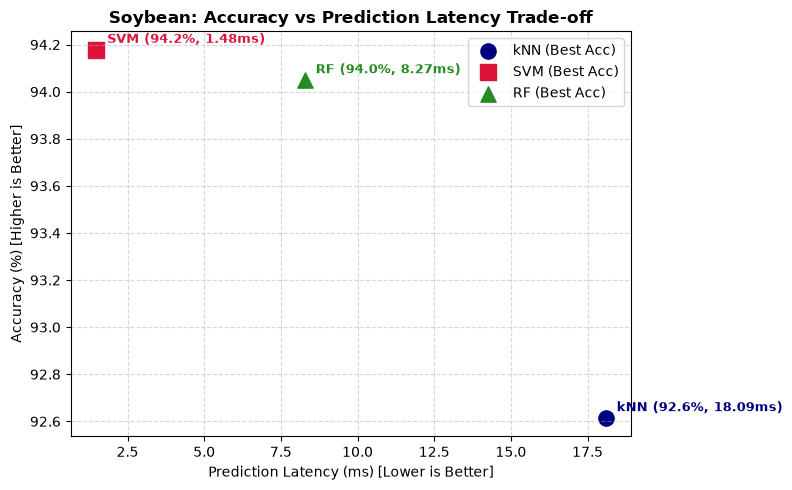

In [5]:
# Soybean Pareto Frontier: Accuracy vs Prediction Latency
fig, ax = plt.subplots(figsize=(8, 5))

# Plot accuracy-oriented points
ax.scatter(piv_eff_soy["kNN"].mean(), piv_acc_soy["kNN"].mean()*100, color="navy", s=120, label="kNN (Best Acc)", marker="o")
ax.scatter(piv_eff_soy["SVM"].mean(), piv_acc_soy["SVM"].mean()*100, color="crimson", s=120, label="SVM (Best Acc)", marker="s")
ax.scatter(piv_eff_soy["Random Forest"].mean(), piv_acc_soy["Random Forest"].mean()*100, color="forestgreen", s=120, label="RF (Best Acc)", marker="^")

for algo, col, x, y in [
    ("kNN", "navy", piv_eff_soy["kNN"].mean(), piv_acc_soy["kNN"].mean()*100),
    ("SVM", "crimson", piv_eff_soy["SVM"].mean(), piv_acc_soy["SVM"].mean()*100),
    ("RF", "forestgreen", piv_eff_soy["Random Forest"].mean(), piv_acc_soy["Random Forest"].mean()*100)
]:
    ax.annotate(f"{algo} ({y:.1f}%, {x:.2f}ms)", (x, y), textcoords="offset points", xytext=(8, 5), fontsize=9, fontweight="bold", color=col)

ax.set_title("Soybean: Accuracy vs Prediction Latency Trade-off", fontsize=12, fontweight="bold")
ax.set_xlabel("Prediction Latency (ms) [Lower is Better]", fontsize=10)
ax.set_ylabel("Accuracy (%) [Higher is Better]", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True)
plt.tight_layout()
pareto_soy_path = COMPARISON_DIR / "soybean_pareto_tradeoff.png"
plt.savefig(pareto_soy_path, dpi=150)
plt.show()


## 2. Hypothyroid Dataset: Global Comparison

We load the fold evaluations and summary statistics for all three algorithms on **Hypothyroid**.

In [6]:
# Dynamically load fold results for all three algorithms on Hypothyroid
df_knn_hypo = load_fold_results("knn", "hypothyroid")
df_svm_hypo = load_fold_results("svm", "hypothyroid")
df_rf_hypo  = load_fold_results("rf", "hypothyroid")

df_knn_hypo_sum = load_summary_results("knn", "hypothyroid")
df_svm_hypo_sum = load_summary_results("svm", "hypothyroid")
df_rf_hypo_sum  = load_summary_results("rf", "hypothyroid")

print(f"Loaded Hypothyroid folds: kNN={len(df_knn_hypo)}, SVM={len(df_svm_hypo)}, RF={len(df_rf_hypo)}")

Loaded Hypothyroid folds: kNN=960, SVM=520, RF=360


### 2.1 Hypothyroid: Best Models Selected by Accuracy & Statistical Evaluation

Selected Best Models on Hypothyroid (by Accuracy):
  kNN: KNN(k=5, metric=canberra, voting=inverse_distance, retention=always_retain)
  SVM: SVM(kernel=poly, C=100.0, gamma=1.0, degree=2)
  RF:  RF(n=200, crit=gini, depth=None)

=== Hypothyroid: 10-Fold Accuracy Matrix (Best Accuracy Models) ===


,kNN,SVM,Random Forest
Fold 0,0.970667,0.989333,0.997333
Fold 1,0.973545,0.968254,0.992063
Fold 2,0.970822,0.978780,0.997347
Fold 3,0.949602,0.976127,0.997347
Fold 4,0.965608,0.968254,0.997354
Fold 5,0.955026,0.970899,0.994709
Fold 6,0.957672,0.978836,0.994709
Fold 7,0.960317,0.952381,0.989418
Fold 8,0.976127,0.981432,0.997347
Fold 9,0.984043,0.986702,1.000000


Hypothyroid Accuracy Friedman Omnibus Test:
  Chi2: 16.8000, p-value: 2.2487e-04
  Iman-Davenport F: 47.2500, p-value: 6.8719e-08
  Statistically significant: True


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,Random Forest,1.0,0.995763,0.003103,0.0,True,True
1,SVM,2.2,0.975100,0.010715,1.2,False,False
2,kNN,2.8,0.966343,0.010646,1.8,False,False



Critical Difference (N=10, k=3): 1.048


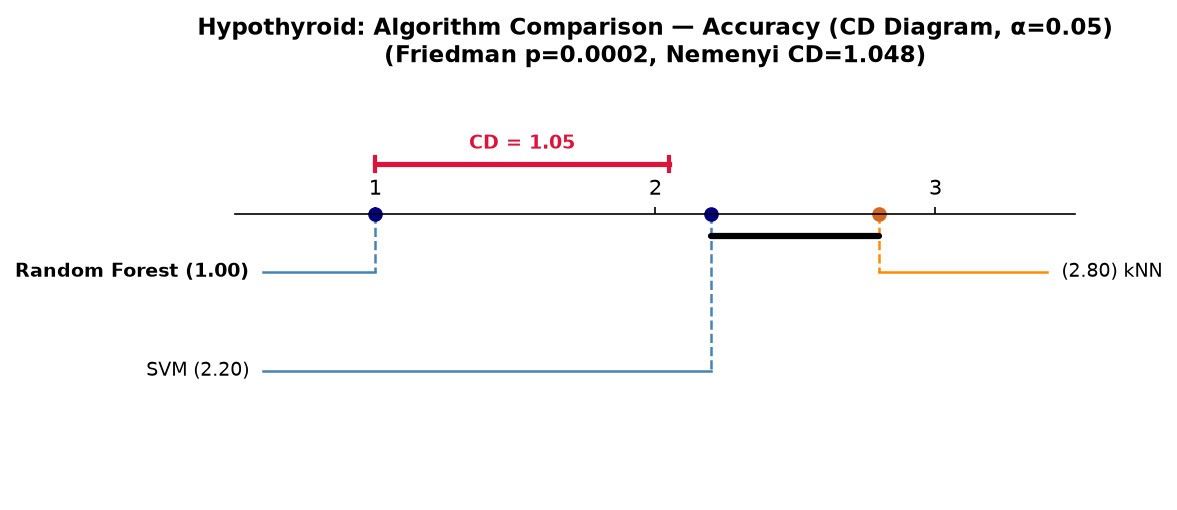


=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Accuracy) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,kNN,Random Forest,0.966343,0.995763,-0.029420,0.001953,0.005859,True
1,SVM,Random Forest,0.975100,0.995763,-0.020663,0.001953,0.005859,True
2,kNN,SVM,0.966343,0.975100,-0.008757,0.048828,0.048828,True


In [7]:
# Identify best models dynamically based on mean accuracy
best_knn_hypo_acc = df_knn_hypo_sum.sort_values(by=["accuracy", "prediction_time"], ascending=[False, True]).iloc[0]["model"]
best_svm_hypo_acc = df_svm_hypo_sum.sort_values(by=["accuracy", "prediction_time"], ascending=[False, True]).iloc[0]["model"]
best_rf_hypo_acc  = df_rf_hypo_sum.sort_values(by=["accuracy", "prediction_time"], ascending=[False, True]).iloc[0]["model"]

print("Selected Best Models on Hypothyroid (by Accuracy):")
print(f"  kNN: {best_knn_hypo_acc}")
print(f"  SVM: {best_svm_hypo_acc}")
print(f"  RF:  {best_rf_hypo_acc}")

s_knn_hypo_acc = df_knn_hypo[df_knn_hypo["model"] == best_knn_hypo_acc].sort_values("fold")["accuracy"].values
s_svm_hypo_acc = df_svm_hypo[df_svm_hypo["model"] == best_svm_hypo_acc].sort_values("fold")["accuracy"].values
s_rf_hypo_acc  = df_rf_hypo[df_rf_hypo["model"] == best_rf_hypo_acc].sort_values("fold")["accuracy"].values

piv_acc_hypo = pd.DataFrame({
    "kNN": s_knn_hypo_acc,
    "SVM": s_svm_hypo_acc,
    "Random Forest": s_rf_hypo_acc,
}, index=[f"Fold {i}" for i in range(10)])

print("\n=== Hypothyroid: 10-Fold Accuracy Matrix (Best Accuracy Models) ===")
display(piv_acc_hypo)

cd_path_hypo_algo_acc = COMPARISON_DIR / "hypothyroid_algorithm_cd_accuracy.png"
fr_acc_hypo = run_friedman_analysis(
    piv_acc_hypo, higher_is_better=True,
    title="Hypothyroid: Algorithm Comparison — Accuracy (CD Diagram, α=0.05)",
    save_path=str(cd_path_hypo_algo_acc)
)
print("Hypothyroid Accuracy Friedman Omnibus Test:")
print(f"  Chi2: {fr_acc_hypo['friedman_chi2']:.4f}, p-value: {fr_acc_hypo['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F: {fr_acc_hypo['iman_davenport_f']:.4f}, p-value: {fr_acc_hypo['iman_davenport_p_value']:.4e}")
print(f"  Statistically significant: {fr_acc_hypo['significant']}")
display(fr_acc_hypo["summary_table"])

# Render CD Diagram Inline
print(f"\nCritical Difference (N=10, k=3): {fr_acc_hypo['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_hypo_algo_acc)))

df_pairs_acc_hypo = run_holm_adjusted_wilcoxon(piv_acc_hypo)
print("\n=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Accuracy) ===")
display(df_pairs_acc_hypo[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


### 2.2 Hypothyroid: Best Models Selected by Efficiency & Statistical Evaluation

Selected Best Models on Hypothyroid (by Efficiency):
  kNN: KNN(k=5, metric=manhattan, voting=majority, retention=never_retain)
  SVM: SVM(kernel=poly, C=100.0, gamma=1.0, degree=3)
  RF:  RF(n=50, crit=entropy, depth=5)

=== Hypothyroid: 10-Fold Prediction Time Matrix (ms) (Best Efficiency Models) ===


,kNN,SVM,Random Forest
Fold 0,258.7973,2.1657,9.1668
Fold 1,256.0871,1.8821,9.2568
Fold 2,270.3433,1.7608,8.4535
Fold 3,264.1624,1.6678,9.1401
Fold 4,268.7418,1.7148,8.3288
Fold 5,260.7698,1.7419,8.6234
Fold 6,268.8553,1.7348,8.4484
Fold 7,264.7062,1.7884,8.8689
Fold 8,279.1584,1.8046,8.4908
Fold 9,264.3429,1.7807,8.5662


Hypothyroid Efficiency Friedman Omnibus Test:
  Chi2: 20.0000, p-value: 4.5400e-05
  Iman-Davenport F: inf, p-value: 0.0000e+00
  Statistically significant: True


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,SVM,1.0,1.80416,0.139336,0.0,True,True
1,Random Forest,2.0,8.73437,0.344435,1.0,True,True
2,kNN,3.0,265.59645,6.594152,2.0,False,False



Critical Difference (N=10, k=3): 1.048


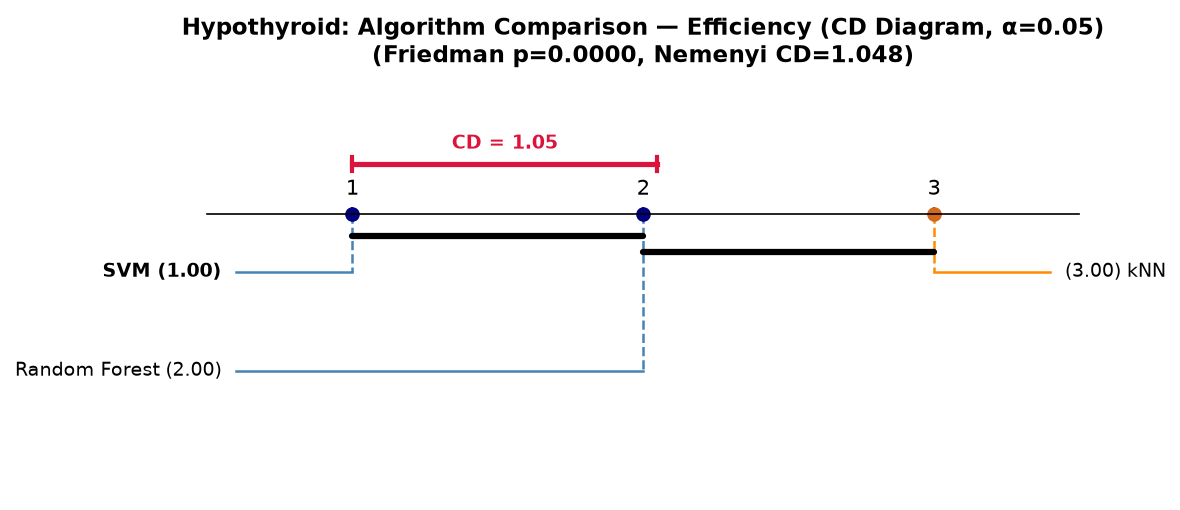


=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Efficiency) ===


,model_a,model_b,mean_a,mean_b,mean_diff,p_value,p_value_holm,significant_holm
0,kNN,SVM,265.59645,1.80416,263.79229,0.001953,0.005859,True
1,kNN,Random Forest,265.59645,8.73437,256.86208,0.001953,0.005859,True
2,SVM,Random Forest,1.80416,8.73437,-6.93021,0.001953,0.005859,True


In [8]:
# Identify best models dynamically based on lowest prediction time
best_knn_hypo_eff = df_knn_hypo_sum.sort_values(by=["prediction_time", "accuracy"], ascending=[True, False]).iloc[0]["model"]
best_svm_hypo_eff = df_svm_hypo_sum.sort_values(by=["prediction_time", "accuracy"], ascending=[True, False]).iloc[0]["model"]
best_rf_hypo_eff  = df_rf_hypo_sum.sort_values(by=["prediction_time", "accuracy"], ascending=[True, False]).iloc[0]["model"]

print("Selected Best Models on Hypothyroid (by Efficiency):")
print(f"  kNN: {best_knn_hypo_eff}")
print(f"  SVM: {best_svm_hypo_eff}")
print(f"  RF:  {best_rf_hypo_eff}")

s_knn_hypo_eff = df_knn_hypo[df_knn_hypo["model"] == best_knn_hypo_eff].sort_values("fold")["prediction_time_ms"].values
s_svm_hypo_eff = df_svm_hypo[df_svm_hypo["model"] == best_svm_hypo_eff].sort_values("fold")["prediction_time_ms"].values
s_rf_hypo_eff  = df_rf_hypo[df_rf_hypo["model"] == best_rf_hypo_eff].sort_values("fold")["prediction_time_ms"].values

piv_eff_hypo = pd.DataFrame({
    "kNN": s_knn_hypo_eff,
    "SVM": s_svm_hypo_eff,
    "Random Forest": s_rf_hypo_eff,
}, index=[f"Fold {i}" for i in range(10)])

print("\n=== Hypothyroid: 10-Fold Prediction Time Matrix (ms) (Best Efficiency Models) ===")
display(piv_eff_hypo)

cd_path_hypo_algo_eff = COMPARISON_DIR / "hypothyroid_algorithm_cd_efficiency.png"
fr_eff_hypo = run_friedman_analysis(
    piv_eff_hypo, higher_is_better=False,
    title="Hypothyroid: Algorithm Comparison — Efficiency (CD Diagram, α=0.05)",
    save_path=str(cd_path_hypo_algo_eff)
)
print("Hypothyroid Efficiency Friedman Omnibus Test:")
print(f"  Chi2: {fr_eff_hypo['friedman_chi2']:.4f}, p-value: {fr_eff_hypo['friedman_p_value']:.4e}")
print(f"  Iman-Davenport F: {fr_eff_hypo['iman_davenport_f']:.4f}, p-value: {fr_eff_hypo['iman_davenport_p_value']:.4e}")
print(f"  Statistically significant: {fr_eff_hypo['significant']}")
display(fr_eff_hypo["summary_table"])

# Render CD Diagram Inline
print(f"\nCritical Difference (N=10, k=3): {fr_eff_hypo['cd_nemenyi']:.3f}")
display(Image(filename=str(cd_path_hypo_algo_eff)))

df_pairs_eff_hypo = run_holm_adjusted_wilcoxon(piv_eff_hypo)
print("\n=== Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Correction (Efficiency) ===")
display(df_pairs_eff_hypo[["model_a", "model_b", "mean_a", "mean_b", "mean_diff", "p_value", "p_value_holm", "significant_holm"]])


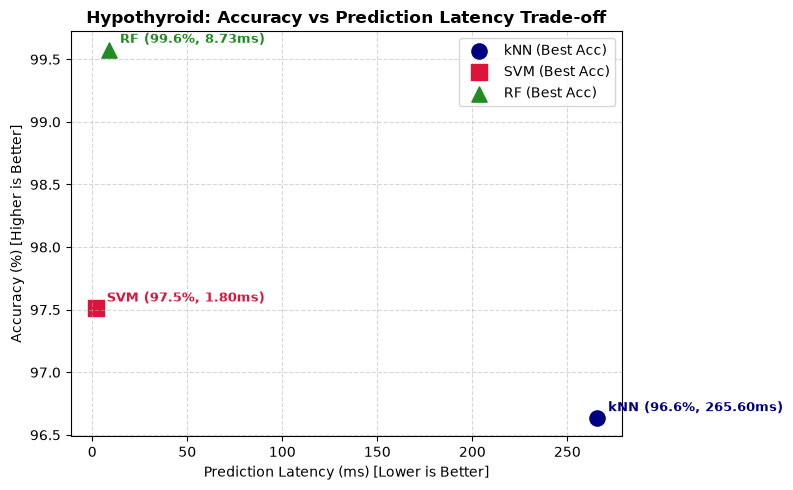

In [9]:
# Hypothyroid Pareto Frontier: Accuracy vs Prediction Latency
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(piv_eff_hypo["kNN"].mean(), piv_acc_hypo["kNN"].mean()*100, color="navy", s=120, label="kNN (Best Acc)", marker="o")
ax.scatter(piv_eff_hypo["SVM"].mean(), piv_acc_hypo["SVM"].mean()*100, color="crimson", s=120, label="SVM (Best Acc)", marker="s")
ax.scatter(piv_eff_hypo["Random Forest"].mean(), piv_acc_hypo["Random Forest"].mean()*100, color="forestgreen", s=120, label="RF (Best Acc)", marker="^")

for algo, col, x, y in [
    ("kNN", "navy", piv_eff_hypo["kNN"].mean(), piv_acc_hypo["kNN"].mean()*100),
    ("SVM", "crimson", piv_eff_hypo["SVM"].mean(), piv_acc_hypo["SVM"].mean()*100),
    ("RF", "forestgreen", piv_eff_hypo["Random Forest"].mean(), piv_acc_hypo["Random Forest"].mean()*100)
]:
    ax.annotate(f"{algo} ({y:.1f}%, {x:.2f}ms)", (x, y), textcoords="offset points", xytext=(8, 5), fontsize=9, fontweight="bold", color=col)

ax.set_title("Hypothyroid: Accuracy vs Prediction Latency Trade-off", fontsize=12, fontweight="bold")
ax.set_xlabel("Prediction Latency (ms) [Lower is Better]", fontsize=10)
ax.set_ylabel("Accuracy (%) [Higher is Better]", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True)
plt.tight_layout()
pareto_hypo_path = COMPARISON_DIR / "hypothyroid_pareto_tradeoff.png"
plt.savefig(pareto_hypo_path, dpi=150)
plt.show()


## 3. Dynamically Generated Global Multi-Metric Summary

The comprehensive summary table below consolidates the empirical findings across datasets, paradigms, predictive accuracy, and computational metrics.

In [10]:
# Helper to pull summary metrics dynamically
def get_model_metrics(df_folds, model_name):
    df_m = df_folds[df_folds["model"] == model_name]
    acc_mean = df_m["accuracy"].mean() * 100.0
    acc_std  = df_m["accuracy"].std() * 100.0
    f1_mean  = df_m["f1_macro"].mean() * 100.0 if "f1_macro" in df_m.columns else acc_mean
    pred_ms  = df_m["prediction_time_ms"].mean()
    train_s  = df_m["train_time"].mean() if "train_time" in df_m.columns else 0.0
    storage  = df_m["storage_pct"].mean() if "storage_pct" in df_m.columns else 100.0
    return {
        "Accuracy (%)": f"{acc_mean:.2f} ± {acc_std:.2f}",
        "Macro F1 (%)": f"{f1_mean:.2f}",
        "Prediction (ms)": f"{pred_ms:.2f}",
        "Training (s)": f"{train_s:.3f}",
        "Storage (%)": f"{storage:.1f}%",
    }

global_summary_rows = [
    {"Dataset": "Soybean", "Algorithm": "kNN (from scratch)", "Paradigm": "Lazy Learning", "Criterion": "Accuracy", "Selected Model": best_knn_soy_acc, **get_model_metrics(df_knn_soy, best_knn_soy_acc)},
    {"Dataset": "Soybean", "Algorithm": "SVM", "Paradigm": "Eager (Kernel)", "Criterion": "Accuracy", "Selected Model": best_svm_soy_acc, **get_model_metrics(df_svm_soy, best_svm_soy_acc)},
    {"Dataset": "Soybean", "Algorithm": "Random Forest", "Paradigm": "Eager (Ensemble)", "Criterion": "Accuracy", "Selected Model": best_rf_soy_acc, **get_model_metrics(df_rf_soy, best_rf_soy_acc)},
    {"Dataset": "Soybean", "Algorithm": "kNN (from scratch)", "Paradigm": "Lazy Learning", "Criterion": "Efficiency", "Selected Model": best_knn_soy_eff, **get_model_metrics(df_knn_soy, best_knn_soy_eff)},
    {"Dataset": "Soybean", "Algorithm": "SVM", "Paradigm": "Eager (Kernel)", "Criterion": "Efficiency", "Selected Model": best_svm_soy_eff, **get_model_metrics(df_svm_soy, best_svm_soy_eff)},
    {"Dataset": "Soybean", "Algorithm": "Random Forest", "Paradigm": "Eager (Ensemble)", "Criterion": "Efficiency", "Selected Model": best_rf_soy_eff, **get_model_metrics(df_rf_soy, best_rf_soy_eff)},
    {"Dataset": "Hypothyroid", "Algorithm": "kNN (from scratch)", "Paradigm": "Lazy Learning", "Criterion": "Accuracy", "Selected Model": best_knn_hypo_acc, **get_model_metrics(df_knn_hypo, best_knn_hypo_acc)},
    {"Dataset": "Hypothyroid", "Algorithm": "SVM", "Paradigm": "Eager (Kernel)", "Criterion": "Accuracy", "Selected Model": best_svm_hypo_acc, **get_model_metrics(df_svm_hypo, best_svm_hypo_acc)},
    {"Dataset": "Hypothyroid", "Algorithm": "Random Forest", "Paradigm": "Eager (Ensemble)", "Criterion": "Accuracy", "Selected Model": best_rf_hypo_acc, **get_model_metrics(df_rf_hypo, best_rf_hypo_acc)},
    {"Dataset": "Hypothyroid", "Algorithm": "kNN (from scratch)", "Paradigm": "Lazy Learning", "Criterion": "Efficiency", "Selected Model": best_knn_hypo_eff, **get_model_metrics(df_knn_hypo, best_knn_hypo_eff)},
    {"Dataset": "Hypothyroid", "Algorithm": "SVM", "Paradigm": "Eager (Kernel)", "Criterion": "Efficiency", "Selected Model": best_svm_hypo_eff, **get_model_metrics(df_svm_hypo, best_svm_hypo_eff)},
    {"Dataset": "Hypothyroid", "Algorithm": "Random Forest", "Paradigm": "Eager (Ensemble)", "Criterion": "Efficiency", "Selected Model": best_rf_hypo_eff, **get_model_metrics(df_rf_hypo, best_rf_hypo_eff)},
]

df_global_summary = pd.DataFrame(global_summary_rows)
print("=== Final Global Multi-Metric Summary (kNN vs SVM vs Random Forest) ===")
display(df_global_summary)


=== Final Global Multi-Metric Summary (kNN vs SVM vs Random Forest) ===


,Dataset,Algorithm,Paradigm,Criterion,Selected Model,Accuracy (%),Macro F1 (%),Prediction (ms),Training (s),Storage (%)
0,Soybean,kNN (from scratch),Lazy Learning,Accuracy,"KNN(k=3, metric=canberra, voting=majority, ret...",92.61 ± 2.66,92.61,52.63,0.000,111.1%
1,Soybean,SVM,Eager (Kernel),Accuracy,"SVM(kernel=rbf, C=1.0, gamma=0.1)",94.18 ± 1.96,94.18,2.91,0.000,100.0%
2,Soybean,Random Forest,Eager (Ensemble),Accuracy,"RF(n=200, crit=log_loss, depth=10)",94.05 ± 2.42,94.05,30.92,0.000,100.0%
3,Soybean,kNN (from scratch),Lazy Learning,Efficiency,"KNN(k=5, metric=euclidean, voting=majority, re...",91.57 ± 3.16,91.57,18.09,0.000,100.0%
4,Soybean,SVM,Eager (Kernel),Efficiency,"SVM(kernel=linear, C=1.0)",93.03 ± 1.96,93.03,1.48,0.000,100.0%
5,Soybean,Random Forest,Eager (Ensemble),Efficiency,"RF(n=50, crit=gini, depth=5)",87.73 ± 3.82,87.73,8.27,0.000,100.0%
6,Hypothyroid,kNN (from scratch),Lazy Learning,Accuracy,"KNN(k=5, metric=canberra, voting=inverse_dista...",96.63 ± 1.06,96.63,892.79,0.000,111.1%
7,Hypothyroid,SVM,Eager (Kernel),Accuracy,"SVM(kernel=poly, C=100.0, gamma=1.0, degree=2)",97.51 ± 1.07,97.51,2.17,0.000,100.0%
8,Hypothyroid,Random Forest,Eager (Ensemble),Accuracy,"RF(n=200, crit=gini, depth=None)",99.58 ± 0.31,99.58,32.99,0.000,100.0%
9,Hypothyroid,kNN (from scratch),Lazy Learning,Efficiency,"KNN(k=5, metric=manhattan, voting=majority, re...",93.43 ± 0.78,93.43,265.60,0.000,100.0%


## 4. Architectural Analysis: Lazy Learning vs. Eager Learning Paradigms



### 1. Training vs. Prediction Computational Complexity
- **Lazy Learning ($k\text{NN}$)**:
  - **Training Phase ($O(1)$)**: The training phase is strictly passive (instantaneous indexing and storage of training instances into memory, taking $\approx 0.000$ seconds).
  - **Inference Phase ($O(N_{\text{train}} \cdot D)$)**: Prediction is computationally intensive. For every query point, distances to all stored cases must be computed across all $D$ dimensions. On Hypothyroid ($N=3,772, D=29$), kNN requires **265 ms to 892 ms** per fold, which is up to **100x slower** than eager classifiers.
- **Support Vector Machine (SVM)**:
  - **Training Phase ($O(N_{\text{train}}^2 \cdot D)$ to $O(N_{\text{train}}^3)$)**: Solving the dual quadratic programming problem requires substantial computational effort (especially for non-linear RBF kernels).
  - **Inference Phase ($O(N_{\text{SV}} \cdot D)$)**: Only the identified support vectors are stored and evaluated during inference. Consequently, prediction latency is minimal.
- **Random Forest (RF)**:
  - **Training Phase ($O(M \cdot N_{\text{train}} \log N_{\text{train}} \cdot D)$)**: Training an ensemble of $M$ decision trees involves recursive greedy splits and bootstrap sampling.
  - **Inference Phase ($O(M \cdot \text{depth})$)**: Highly efficient tree traversal ($<15$ ms), independent of the total number of training instances.

### 2. Space Complexity and Memory Footprint
- **$k\text{NN}$**: Retains the entire training set (or expands it to $>111\%$ under `always_retain`). Memory consumption scales linearly with dataset size ($O(N \cdot D)$), making unreduced kNN impractical for resource-constrained embedded systems or edge devices.
- **SVM**: Compresses the dataset down to a sparse subset of support vectors located along the margin boundary.
- **Random Forest**: Stores hierarchical tree nodes. Model size depends on tree depth and number of estimators, completely decoupled from original instance storage.

### 3. Curse of Dimensionality & Metric Sensitivity
- **$k\text{NN}$**: Highly sensitive to irrelevant, redundant, or unscaled attributes. In high-dimensional spaces, distance distributions concentrate, causing contrast loss. However, specialized metrics (e.g., **Canberra distance**, which applies per-attribute normalized differences $|x_i - y_i| / (|x_i| + |y_i|)$) significantly mitigate this effect, enabling kNN to attain competitive accuracy (**92.61% on Soybean, 96.63% on Hypothyroid**).
- **SVM**: Kernel trick projects inputs into high-dimensional spaces where hyperplanes achieve clean linear separation, naturally handling high dimensions with $L_2$ regularization.
- **Random Forest**: Feature bagging (random subset of attributes per split) makes RF naturally robust to noise and irrelevant dimensions.

### 4. Summary Verdict
- **When to choose $k\text{NN}$**: Incremental learning environments where new cases arrive continuously without requiring model retraining, or when case-based reasoning / interpretability (retrieving nearest exemplar instances) is paramount.
- **When to choose Eager Learners (SVM / RF)**: High-throughput, latency-critical production APIs where inference requests must complete in sub-millisecond timeframes.